
---

# Import Libraries

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    classification_report, accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score, roc_auc_score,
    davies_bouldin_score, calinski_harabasz_score
)

from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



---

#  Load and Inspect the Dataset


---




In [2]:
# Load the dataset
# Download the dataset from Kaggle (link in README) and place it in the data/ folder
file_path = "../data/global air pollution dataset.csv"
df = pd.read_csv(file_path)

df.head()

,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country             23036 non-null  object
 1   City                23462 non-null  object
 2   AQI Value           23463 non-null  int64 
 3   AQI Category        23463 non-null  object
 4   CO AQI Value        23463 non-null  int64 
 5   CO AQI Category     23463 non-null  object
 6   Ozone AQI Value     23463 non-null  int64 
 7   Ozone AQI Category  23463 non-null  object
 8   NO2 AQI Value       23463 non-null  int64 
 9   NO2 AQI Category    23463 non-null  object
 10  PM2.5 AQI Value     23463 non-null  int64 
 11  PM2.5 AQI Category  23463 non-null  object
dtypes: int64(5), object(7)
memory usage: 2.1+ MB


---

#columns review

---

In [4]:
# List of column names
print(" Column Names:")
print(df.columns.tolist())

# Check for numerical and categorical columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("\n Numerical Columns:", num_cols)
print(" Categorical Columns:", cat_cols)

 Column Names:
['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category']

 Numerical Columns: ['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']
 Categorical Columns: ['Country', 'City', 'AQI Category', 'CO AQI Category', 'Ozone AQI Category', 'NO2 AQI Category', 'PM2.5 AQI Category']


---

#Data preprocessing

---

In [5]:
# ===== Data Cleaning and Preprocessing =====

# Handle Missing Values

# Fill numeric columns with the mean
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Fill categorical columns with the most frequent value
cat_cols = df.select_dtypes(include=['object']).columns
if len(cat_cols) > 0:
    mode_values = df[cat_cols].mode()
    if not mode_values.empty:
        df[cat_cols] = df[cat_cols].fillna(mode_values.iloc[0])

# Drop duplicates
df.drop_duplicates(inplace=True)

# Process "Time Period" column if it exists
if 'Time Period' in df.columns:
    # Extract year
    df['Year'] = df['Time Period'].str.extract(r'(\d{4})').astype(float).astype('Int64')

    # Flag annual records
    df['Is_Annual'] = df['Time Period'].str.contains('Annual Average', na=False).astype(int)

    # Extract and encode season
    season_mapping = {'Winter': 1, 'Spring': 2, 'Summer': 3, 'Fall': 4}
    df['Season'] = df['Time Period'].str.extract(r'(Winter|Spring|Summer|Fall)')
    df['Season'] = df['Season'].map(season_mapping).fillna(0).astype(int)

#  Drop columns that are completely missing
df.dropna(axis=1, how='all', inplace=True)

# 5. Final check and report
print(f" Dropped fully empty columns.")
print(f"Remaining Missing Values: {df.isnull().sum().sum()}")
print(" Data Cleaning Complete!")


 Dropped fully empty columns.
Remaining Missing Values: 0
 Data Cleaning Complete!


##Normalization

In [6]:
features_to_normalize = [
    'AQI Value',
    'CO AQI Value',
    'Ozone AQI Value',
    'NO2 AQI Value',
    'PM2.5 AQI Value'
]

scaler = MinMaxScaler()
df[features_to_normalize] = scaler.fit_transform(df[features_to_normalize])

print(" Normalization Complete.")


 Normalization Complete.


## Feature Selection

In [7]:


#  Select numeric features and the target variable
X = df[[
    'AQI Value',
    'CO AQI Value',
    'Ozone AQI Value',
    'NO2 AQI Value',
    'PM2.5 AQI Value'
]]
y = df['AQI Category']  # Target for classification

#  Encode the target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Apply SelectKBest with ANOVA F-test to select top 3 features
selector = SelectKBest(score_func=f_classif, k=3)
X_selected = selector.fit_transform(X, y_encoded)

# Print selected feature names
selected_features = X.columns[selector.get_support()]
print(" Selected Features:", list(selected_features))


 Selected Features: ['AQI Value', 'Ozone AQI Value', 'PM2.5 AQI Value']


## encoding

In [8]:


# Define categorical columns
categorical_cols = [
    'Country', 'City',
    'AQI Category', 'CO AQI Category',
    'Ozone AQI Category', 'NO2 AQI Category',
    'PM2.5 AQI Category'
]

# Initialize LabelEncoder
le = LabelEncoder()

# Apply Label Encoding to each categorical column
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print("All categorical columns have been label-encoded.")


All categorical columns have been label-encoded.


---

# Standardizing the data

---

In [9]:
X = df[[
    'AQI Value',
    'CO AQI Value',
    'Ozone AQI Value',
    'NO2 AQI Value',
    'PM2.5 AQI Value'
]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

---

#Elbow Method

---


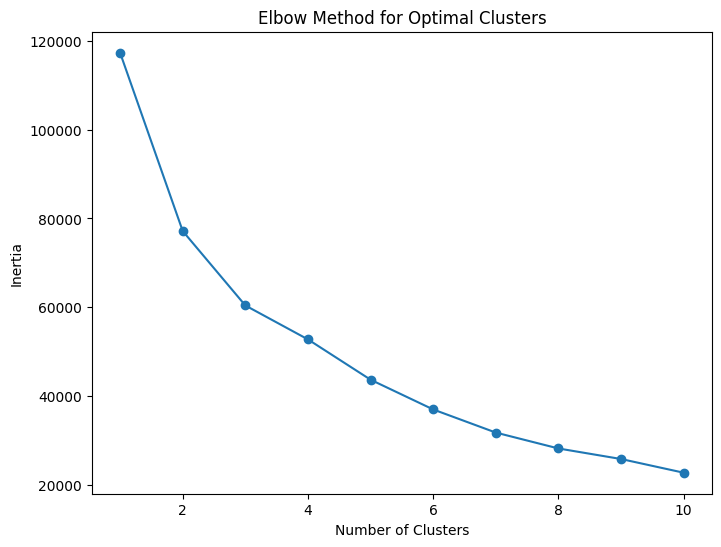

In [10]:
# Calculate inertia for different cluster values
inertia = []
range_n_clusters = range(1, 11)  # Try clusters from 1 to 10

for n_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Graph
plt.figure(figsize=(8,6))
plt.plot(range_n_clusters, inertia, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

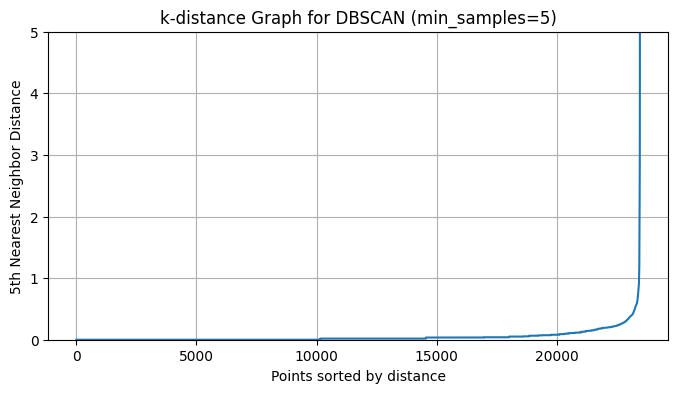

In [44]:
#  Find optimal eps using Nearest Neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort and plot k-distance
distances = np.sort(distances[:, 1])  # 5th nearest neighbor
plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.ylim(0, 5)
plt.title("k-distance Graph for DBSCAN (min_samples=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.grid(True)
plt.show()


---

#  KMeans and GMM Clustering with PCA Visualization

___

In [45]:
# Define optimal number of clusters
optimal_clusters = 3

# Initialize empty lists to store best scores
best_kmeans_score = -1
best_gmm_score = -1

# Test multiple random_state values
best_kmeans_labels = None
best_gmm_labels = None

for seed in [0, 10, 21, 42, 100]:
    # KMeans
    kmeans = KMeans(n_clusters=optimal_clusters, random_state=seed)
    kmeans_labels = kmeans.fit_predict(X_scaled)
    score_kmeans = silhouette_score(X_scaled, kmeans_labels)
    if score_kmeans > best_kmeans_score:
        best_kmeans_score = score_kmeans
        best_kmeans_labels = kmeans_labels

    # GMM
    gmm = GaussianMixture(n_components=optimal_clusters, random_state=seed)
    gmm_labels = gmm.fit_predict(X_scaled)
    score_gmm = silhouette_score(X_scaled, gmm_labels)
    if score_gmm > best_gmm_score:
        best_gmm_score = score_gmm
        best_gmm_labels = gmm_labels

# Final selected labels with best silhouette scores
df["KMeans Label"] = best_kmeans_labels
df["GMM Label"] = best_gmm_labels


best_eps = 0.5

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=best_eps, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)
df["DBSCAN Label"] = dbscan_labels

# Apply PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)



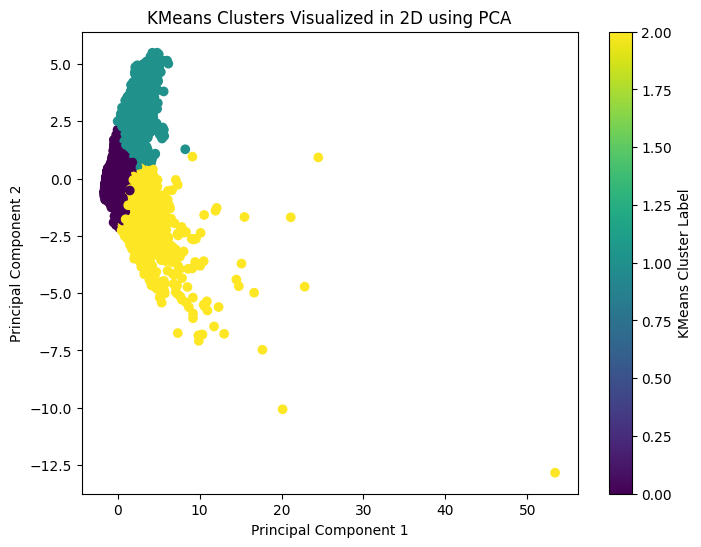

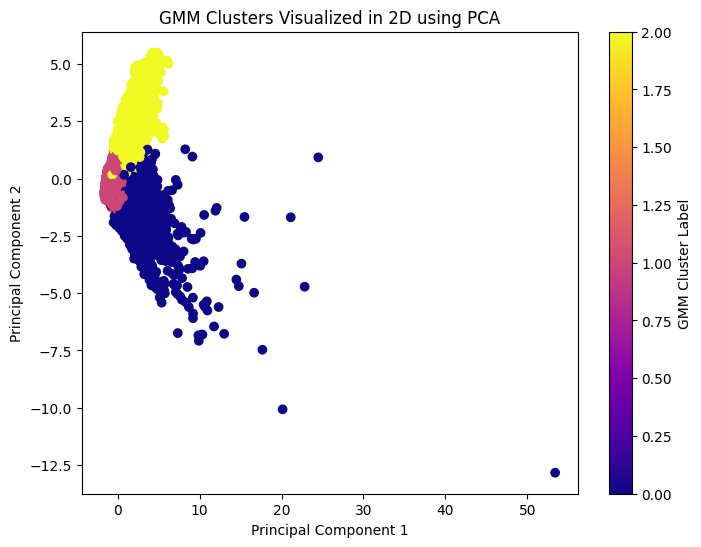

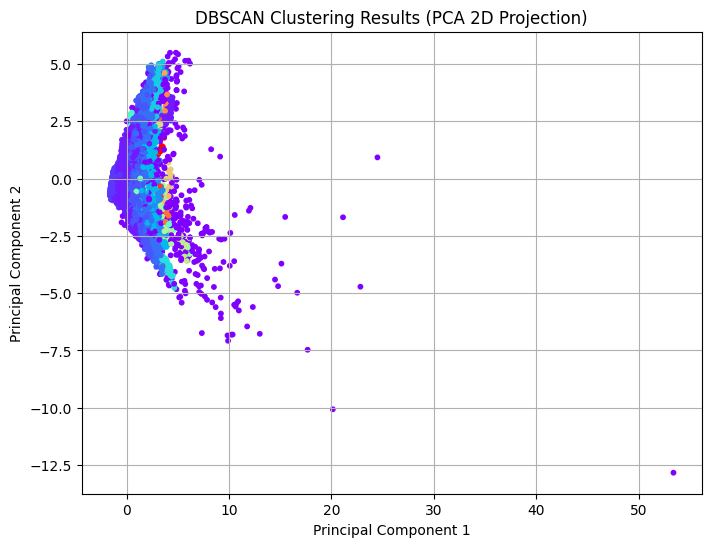

In [46]:
# Plot KMeans Clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["KMeans Label"], cmap='viridis', marker='o')
plt.title('KMeans Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='KMeans Cluster Label')
plt.show()

# Plot GMM Clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["GMM Label"], cmap='plasma', marker='o')
plt.title('GMM Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='GMM Cluster Label')
plt.show()

# Plot DBSCAN clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='rainbow', s=10)
plt.title("DBSCAN Clustering Results (PCA 2D Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()



---

#Evaluation Scores for Each Clustering Model

---

In [47]:
# ===== 1. Compute Evaluation Scores =====
# KMeans
kmeans_silhouette = silhouette_score(X_scaled, df["KMeans Label"])
kmeans_davies = davies_bouldin_score(X_scaled, df["KMeans Label"])
kmeans_calinski = calinski_harabasz_score(X_scaled, df["KMeans Label"])

# GMM
gmm_silhouette = silhouette_score(X_scaled, df["GMM Label"])
gmm_davies = davies_bouldin_score(X_scaled, df["GMM Label"])
gmm_calinski = calinski_harabasz_score(X_scaled, df["GMM Label"])

# DBSCAN (excluding noise)
dbscan_mask = df["DBSCAN Label"] != -1
dbscan_silhouette = silhouette_score(X_scaled[dbscan_mask], df["DBSCAN Label"][dbscan_mask])
dbscan_davies = davies_bouldin_score(X_scaled[dbscan_mask], df["DBSCAN Label"][dbscan_mask])
dbscan_calinski = calinski_harabasz_score(X_scaled[dbscan_mask], df["DBSCAN Label"][dbscan_mask])

# ===== 2. Create Evaluation DataFrame =====
evaluation_results = pd.DataFrame({
    "Model": ["KMeans", "GMM", "DBSCAN"],
    "Silhouette Score": [kmeans_silhouette, gmm_silhouette, dbscan_silhouette],
    "Davies-Bouldin Index": [kmeans_davies, gmm_davies, dbscan_davies],
    "Calinski-Harabasz Score": [kmeans_calinski, gmm_calinski, dbscan_calinski]
})

# ===== 3. Compute Ranking =====
evaluation_results["Silhouette Rank"] = evaluation_results["Silhouette Score"].rank(ascending=False)
evaluation_results["Davies-Bouldin Rank"] = evaluation_results["Davies-Bouldin Index"].rank(ascending=True)
evaluation_results["Calinski-Harabasz Rank"] = evaluation_results["Calinski-Harabasz Score"].rank(ascending=False)

# ===== 4. Average Ranking =====
evaluation_results["Average Rank"] = evaluation_results[
    ["Silhouette Rank", "Davies-Bouldin Rank", "Calinski-Harabasz Rank"]
].mean(axis=1)

# ===== 5. Determine Best Model by Majority & Rank =====
# By individual metric voting
better_silhouette = evaluation_results.loc[evaluation_results["Silhouette Score"].idxmax(), "Model"]
better_davies = evaluation_results.loc[evaluation_results["Davies-Bouldin Index"].idxmin(), "Model"]
better_calinski = evaluation_results.loc[evaluation_results["Calinski-Harabasz Score"].idxmax(), "Model"]

# By majority voting
votes = [better_silhouette, better_davies, better_calinski]
final_model_vote = max(set(votes), key=votes.count)

# By average rank
evaluation_results = evaluation_results.sort_values("Average Rank")
final_model_rank = evaluation_results.iloc[0]["Model"]

# ===== 6. Display Table =====
styled_table = evaluation_results.style.set_table_attributes("style='border:1px solid black;'")\
    .set_caption("Clustering Evaluation Metrics and Rankings")\
    .format(precision=4)\
    .set_table_styles([
        {'selector': 'th', 'props': [('border', '1px solid black')]},
        {'selector': 'td', 'props': [('border', '1px solid black')]}
    ])
display(styled_table)

# ===== 7. Print Summary =====
print("\nEvaluation Summary:")
print(f"• Best Silhouette Score        → {better_silhouette}")
print(f"• Best Davies-Bouldin Index    → {better_davies}")
print(f"• Best Calinski-Harabasz Score → {better_calinski}")
print(f"\nOverall Best Model (by Voting): {final_model_vote}")
print(f"Best Model (by Average Rank): {final_model_rank}")


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Silhouette Rank,Davies-Bouldin Rank,Calinski-Harabasz Rank,Average Rank
0,KMeans,0.6299,0.9078,10514.3907,1.0000,1.0000,1.0000,1.0000
1,GMM,0.5152,1.1893,8482.5782,2.0000,2.0000,2.0000,2.0000
2,DBSCAN,0.0314,1.3997,596.4185,3.0000,3.0000,3.0000,3.0000



Evaluation Summary:
• Best Silhouette Score        → KMeans
• Best Davies-Bouldin Index    → KMeans
• Best Calinski-Harabasz Score → KMeans

Overall Best Model (by Voting): KMeans
Best Model (by Average Rank): KMeans


---

#Supervised usint the clusters in the previos code

---


Define Features, Labels, and Explore Class Distribution

In [48]:
# Define the features and labels
features = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]
X = df[features]
y = df["KMeans Label"]

# Preview the first few rows of features
X.head()

,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
0,0.007519,0.153191,0.000000,0.102
1,0.007519,0.021277,0.010989,0.082
2,0.007519,0.165957,0.021978,0.132
3,0.007519,0.144681,0.000000,0.040
4,0.000000,0.093617,0.000000,0.012


In [20]:
# Count the number of samples in each cluster label
cluster_label_counts = df["KMeans Label"].value_counts()

# Display the counts
cluster_label_counts


,count
KMeans Label,
1,19241
2,2512
0,1710


Scale Features and Split Data into Training and Testing Sets

In [21]:
# Scale the feature values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)


---

#Apply SMOTE to Balance the Dataset

---

In [22]:
# Apply SMOTE to balance the dataset and count resampled labels
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Count the number of samples in each label after resampling
resampled_counts = Counter(y_train_resampled)

df["KMeans Label"].count()


np.int64(23463)

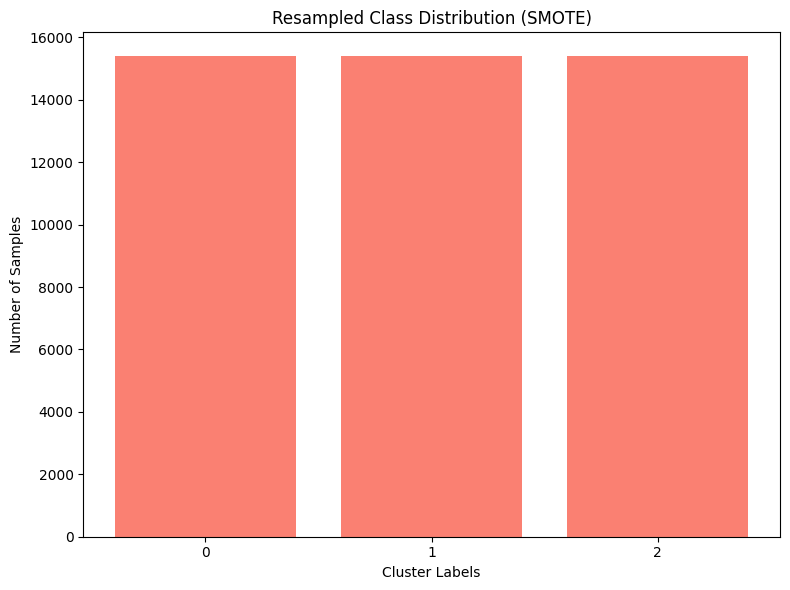

In [23]:
# Get the labels and their corresponding counts
labels = list(resampled_counts.keys())
resampled_values = list(resampled_counts.values())

# Visualize the distribution of labels after SMOTE
plt.figure(figsize=(8, 6))
plt.bar(labels, resampled_values, color='salmon')
plt.title('Resampled Class Distribution (SMOTE)')
plt.xlabel('Cluster Labels')
plt.ylabel('Number of Samples')
plt.xticks(labels)
plt.tight_layout()
plt.show()

---

#Train and Evaluate Multiple Classification Models

---

In [32]:


# Define models
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results
results = []

for name, model in models.items():
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Macro)": report['macro avg']['precision'],
        "Recall (Macro)": report['macro avg']['recall'],
        "F1-score (Macro)": report['macro avg']['f1-score']
    })

    print("=" * 40)
    print(f"Model: {name}")
    print("=" * 40)
    print(classification_report(y_test, y_pred))

# Create DataFrame
results_df = pd.DataFrame(results)

# Highlight best Accuracy and F1-score
def highlight_best(s):
    is_max = s == s.max()
    return ['background-color: lightgreen' if v else '' for v in is_max]

# Style the table
styled_table = results_df.style.set_caption("Model Comparison Results")\
    .format(precision=4)\
    .set_table_attributes("style='border:1px solid black;'")\
    .set_table_styles([
        {'selector': 'th', 'props': [('border', '1px solid black'), ('background-color', '#f2f2f2')]},
        {'selector': 'td', 'props': [('border', '1px solid black')]}
    ])\
    .apply(highlight_best, subset=["Accuracy", "F1-score (Macro)"])

# Display the table
display(styled_table)


Model: Random Forest
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       342
           1       1.00      1.00      1.00      3849
           2       0.98      0.99      0.98       502

    accuracy                           0.99      4693
   macro avg       0.99      0.99      0.99      4693
weighted avg       0.99      0.99      0.99      4693

Model: K-Nearest Neighbors
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       342
           1       1.00      0.99      1.00      3849
           2       0.97      0.99      0.98       502

    accuracy                           0.99      4693
   macro avg       0.98      0.99      0.99      4693
weighted avg       0.99      0.99      0.99      4693

Model: Support Vector Machine
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       342
           1       1.00      0.99      0.99      38

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:13:30] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Model: XGBoost
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       342
           1       1.00      0.99      1.00      3849
           2       0.97      0.99      0.98       502

    accuracy                           0.99      4693
   macro avg       0.98      0.99      0.99      4693
weighted avg       0.99      0.99      0.99      4693



,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Random Forest,0.9940,0.9863,0.9885,0.9874
1,K-Nearest Neighbors,0.9936,0.9779,0.9945,0.9860
2,Support Vector Machine,0.9889,0.9602,0.9943,0.9767
3,XGBoost,0.9938,0.9826,0.9922,0.9874


Visualize Model Accuracy Comparison (Bar Plot)

<ipython-input-25-02f1a89dc830>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="Accuracy", palette="Set2")


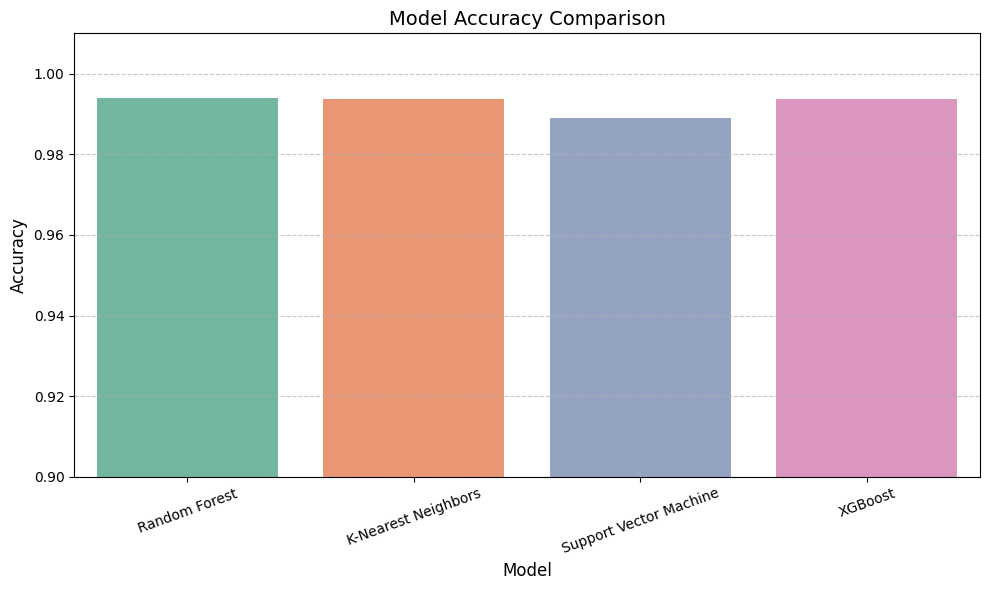

In [25]:
# Visualize Accuracy Comparison of Models
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="Model", y="Accuracy", palette="Set2")

plt.title("Model Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy", fontsize=12)
plt.xlabel("Model", fontsize=12)
plt.xticks(rotation=20)
plt.ylim(0.90, 1.01)  # Adjust based on range
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Overfitting Visualization: Train vs Test Accuracy

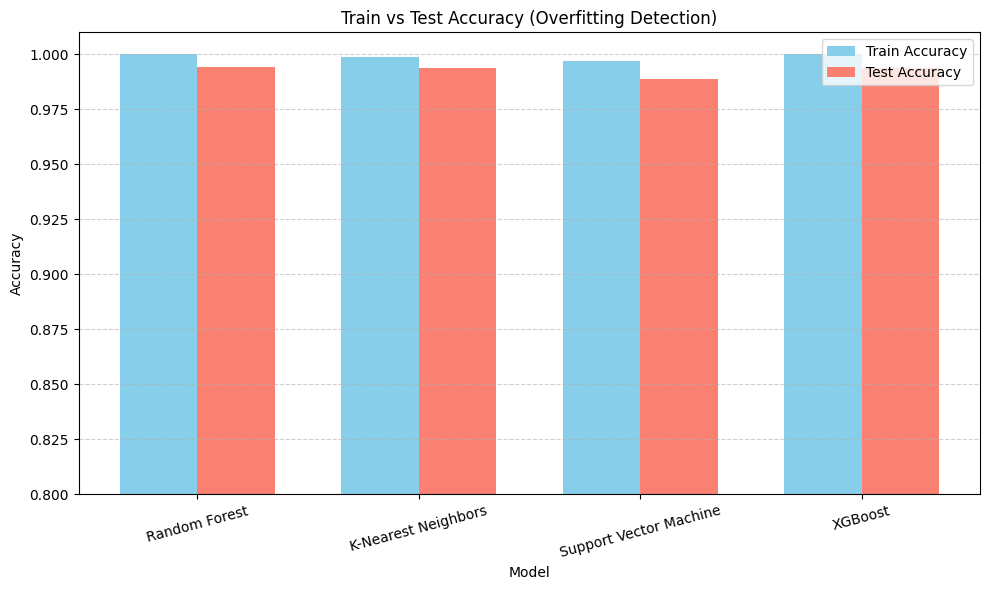

In [26]:
# Collect train and test accuracy without refitting
train_scores = []
test_scores = []

for name, model in models.items():
    train_acc = accuracy_score(y_train_resampled, model.predict(X_train_resampled))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    train_scores.append(train_acc)
    test_scores.append(test_acc)

# Create DataFrame for plotting
overfit_df = pd.DataFrame({
    "Model": list(models.keys()),
    "Train Accuracy": train_scores,
    "Test Accuracy": test_scores
})

# Plot the comparison
plt.figure(figsize=(10, 6))
x = np.arange(len(overfit_df["Model"]))
bar_width = 0.35

plt.bar(x - bar_width/2, overfit_df["Train Accuracy"], width=bar_width, label='Train Accuracy', color='skyblue')
plt.bar(x + bar_width/2, overfit_df["Test Accuracy"], width=bar_width, label='Test Accuracy', color='salmon')

plt.xticks(x, overfit_df["Model"], rotation=15)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy (Overfitting Detection)")
plt.ylim(0.8, 1.01)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

 Learning Curve for the Best Generalizing Model

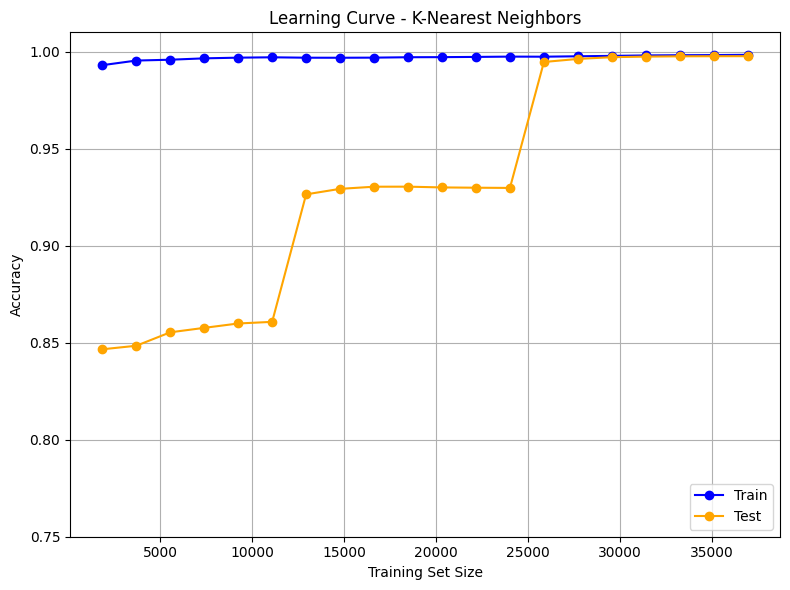

In [27]:
# Ensure Gap column exists
if "Gap" not in overfit_df.columns:
    overfit_df["Gap"] = abs(overfit_df["Train Accuracy"] - overfit_df["Test Accuracy"])

# Get best model (with smallest train-test gap)
best_model_name = overfit_df.loc[overfit_df["Gap"].idxmin(), "Model"]
best_model = models[best_model_name]

# Learning curve
train_sizes, train_scores, test_scores = learning_curve(
    best_model, X_train_resampled, y_train_resampled,
    cv=5, scoring='accuracy', train_sizes=np.linspace(0.05, 1.0, 20), n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Train')
plt.plot(train_sizes, test_mean, 'o-', color='orange', label='Test')
plt.title(f"Learning Curve - {best_model_name}")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.legend(loc='lower right')
plt.grid(True)
plt.ylim(0.75, 1.01)
plt.tight_layout()
plt.show()


---

#SVM Evaluation with SMOTE Using Cross-Validation

---

In [28]:
# Define a pipeline that applies SMOTE then trains SVM
pipeline_svm = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(random_state=42))
])

# Define cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform cross-validation
cv_scores = cross_val_score(pipeline_svm, X_train, y_train, cv=cv, scoring='accuracy')

# Display results with formatting
print("SVM Cross-Validation Accuracy Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\nMean CV Accuracy: {cv_scores.mean():.4f}")


SVM Cross-Validation Accuracy Scores:
  Fold 1: 0.9912
  Fold 2: 0.9925
  Fold 3: 0.9933
  Fold 4: 0.9920
  Fold 5: 0.9899

Mean CV Accuracy: 0.9918


Visualize Confusion Matrix for Each Classification Model

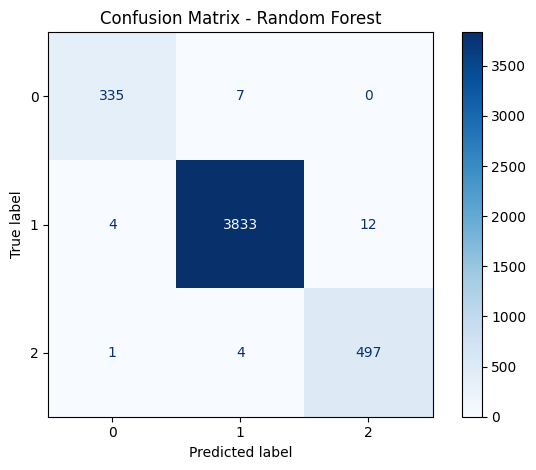

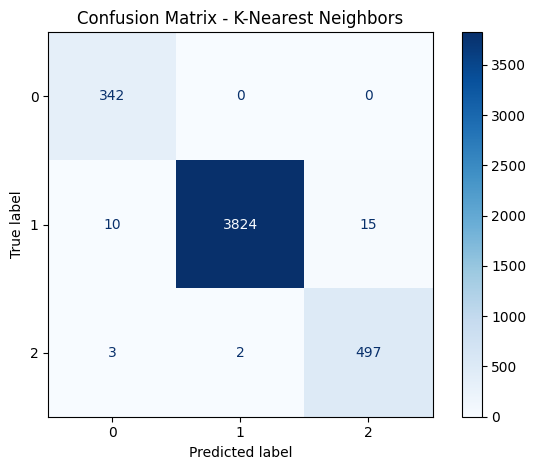

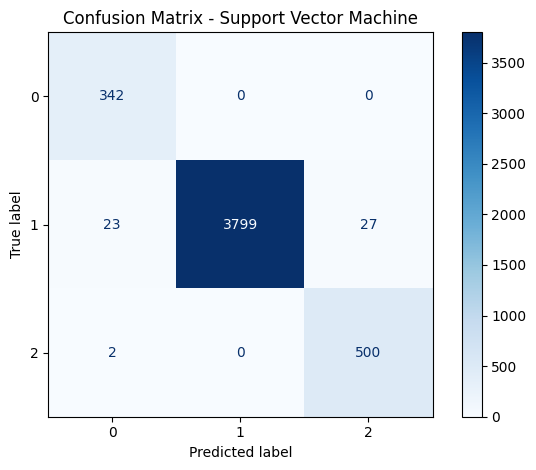

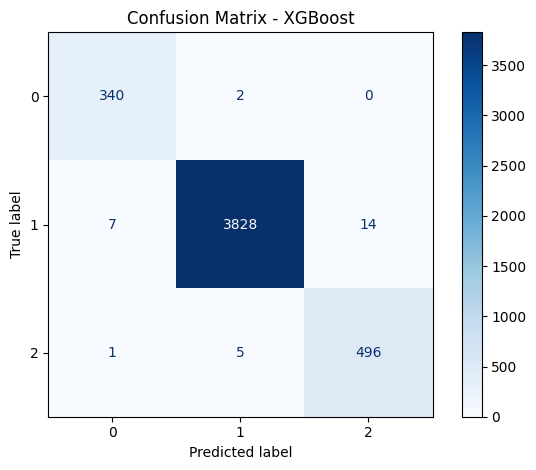

In [29]:
# Plot confusion matrices for each model
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    # Handle class labels dynamically
    labels = model.classes_ if hasattr(model, 'classes_') else [0, 1, 2]

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='Blues', values_format='d')

    plt.title(f'Confusion Matrix - {name}')
    plt.tight_layout()
    plt.show()

Evaluate SVM with Cross-Validated Predictions and ROC-AUC (Multiclass)

In [34]:
# Get predicted labels and decision scores (for ROC-AUC)
y_pred = cross_val_predict(pipeline_svm, X_train, y_train, cv=cv)
y_prob = cross_val_predict(pipeline_svm, X_train, y_train, cv=cv, method='decision_function')

# Convert classification report to DataFrame
report_dict = classification_report(y_train, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).T

# Style the table
styled_report = report_df.style\
    .set_caption("Classification Report (Cross-Validated Predictions)")\
    .format(precision=2)\
    .set_table_attributes("style='border:1px solid black;'")\
    .set_table_styles([
        {'selector': 'th', 'props': [('border', '1px solid black'), ('background-color', '#f5f5f5')]},
        {'selector': 'td', 'props': [('border', '1px solid black')]}
    ])

# Display styled classification report
display(styled_report)

# Compute Multiclass ROC-AUC
y_bin = label_binarize(y_train, classes=np.unique(y_train))
roc_auc = roc_auc_score(y_bin, y_prob, multi_class='ovr')

# Print ROC-AUC result
print(f"\nMulticlass ROC-AUC Score: {round(roc_auc, 4)}")

,precision,recall,f1-score,support
0,0.94,1.00,0.97,1368.00
1,1.00,0.99,1.00,15392.00
2,0.97,1.00,0.98,2010.00
accuracy,0.99,0.99,0.99,0.99
macro avg,0.97,1.00,0.98,18770.00
weighted avg,0.99,0.99,0.99,18770.00



Multiclass ROC-AUC Score: 0.9995


Confusion Matrix for Training Set Predictions

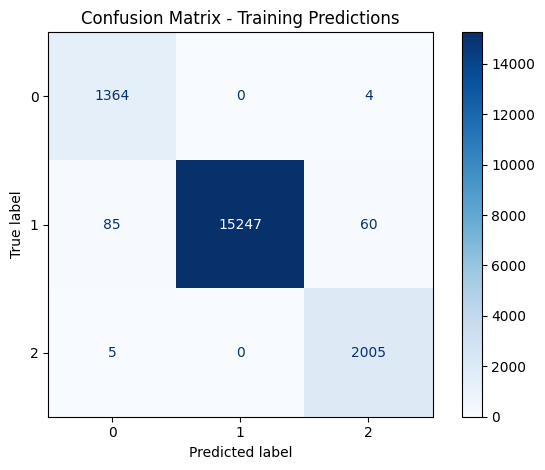

In [35]:
# Compute confusion matrix for training data
cm = confusion_matrix(y_train, y_pred)

# Display the matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Training Predictions")
plt.tight_layout()
plt.show()

---

#Supervised using the target in dataset

---

Prepare Supervised Labels from AQI Category (Label Encoding + Distribution)

In [36]:
# Define the features and target variable
features = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]
X = df[features]

# Encode the AQI category target
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["AQI Category"])

# Display label mapping
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label Mapping:", label_mapping)

# Display encoded class distribution
encoded_counts = pd.Series(y).value_counts()
print("\nEncoded AQI Category Counts:")
print(encoded_counts)

Label Mapping: {np.int64(0): np.int64(0), np.int64(1): np.int64(1), np.int64(2): np.int64(2), np.int64(3): np.int64(3), np.int64(4): np.int64(4), np.int64(5): np.int64(5)}

Encoded AQI Category Counts:
0    9936
2    9231
3    2227
4    1591
5     287
1     191
Name: count, dtype: int64


Preprocess Data with Scaling, Splitting, SMOTE, and Class Distribution Visualization





Resampled class distribution: Counter({np.int64(0): 6955, np.int64(2): 6955, np.int64(4): 6955, np.int64(3): 6955, np.int64(5): 6955, np.int64(1): 6955})


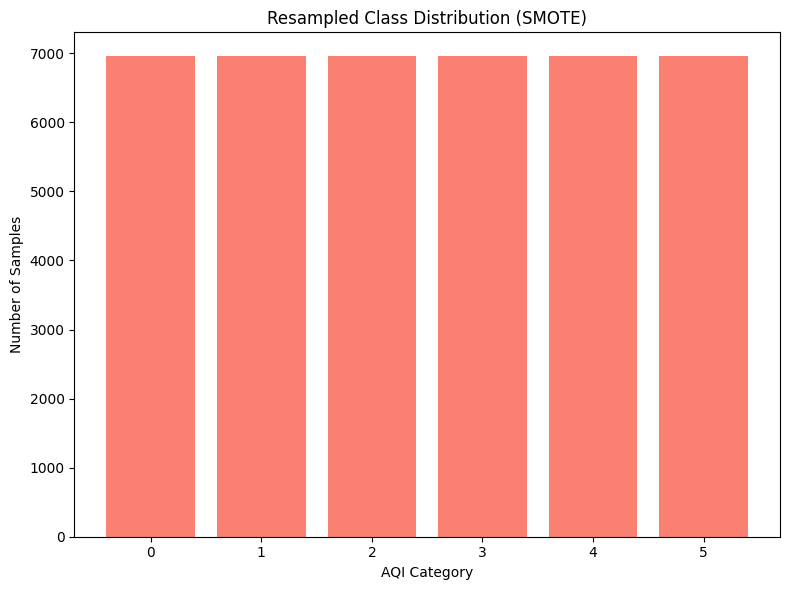

In [37]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# Apply SMOTE to balance the dataset (only on training data)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Display the class distribution after resampling
resampled_counts = Counter(y_train_resampled)
print("Resampled class distribution:", resampled_counts)

# Plot the resampled class distribution
labels = list(resampled_counts.keys())
resampled_values = list(resampled_counts.values())

plt.figure(figsize=(8, 6))
plt.bar(labels, resampled_values, color='salmon')
plt.title('Resampled Class Distribution (SMOTE)')
plt.xlabel('AQI Category')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

Cross-Validation Accuracy Evaluation for Multiple Models

In [38]:
# Define models
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(probability=True),
    "XGBoost": XGBClassifier(use_label_encoder=True, eval_metric='mlogloss')
}

# Set up results dictionary
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate each model
for model_name, model in models.items():
    print(f"Evaluating: {model_name}")
    cv_scores = cross_val_score(model, X_train_resampled, y_train_resampled, cv=cv, scoring='accuracy')
    results[model_name] = {
        "accuracy_scores": cv_scores,
        "mean_accuracy": np.mean(cv_scores)
    }

# Convert results to DataFrame
results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Mean CV Accuracy": [results[m]["mean_accuracy"] for m in results]
}).sort_values(by="Mean CV Accuracy", ascending=False).reset_index(drop=True)

# Style the table
styled_table = results_df.style.set_caption("Mean CV Accuracy for Each Model")\
    .format({"Mean CV Accuracy": "{:.4f}"})\
    .set_table_attributes("style='border:1px solid black;'")\
    .set_table_styles([
        {'selector': 'th', 'props': [('border', '1px solid black'), ('background-color', '#f2f2f2')]},
        {'selector': 'td', 'props': [('border', '1px solid black')]}
    ])\
    .highlight_max(subset=["Mean CV Accuracy"], color='lightgreen')

# Display the styled table
display(styled_table)


Evaluating: Random Forest
Evaluating: K-Nearest Neighbors
Evaluating: Support Vector Machine
Evaluating: XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:17:02] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:17:03] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:17:05] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:17:06] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:17:07] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_e

,Model,Mean CV Accuracy
0,Random Forest,0.9993
1,XGBoost,0.9986
2,K-Nearest Neighbors,0.9858
3,Support Vector Machine,0.9580


Final Model Evaluation Summary: Classification & ROC-AUC

In [39]:
# Fit and evaluate each model
for model_name, model in models.items():
    print("="*60)
    print(f" Fitting and evaluating: {model_name}")

    model.fit(X_train_resampled, y_train_resampled)

    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)

    clf_report = classification_report(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_prob, multi_class='ovr', average='macro')

    results[model_name]["classification_report"] = clf_report
    results[model_name]["roc_auc_score"] = roc_auc

    print(" Classification Report:")
    print(clf_report)
    print(f"Multiclass ROC-AUC Score: {roc_auc:.4f}")
    print()

# ================= Final Summary Table =================
summary_data = []

for model_name, result in results.items():
    summary_data.append({
        "Model": model_name,
        "Mean CV Accuracy": result["mean_accuracy"],
        "Test ROC-AUC": result["roc_auc_score"]
    })

summary_df = pd.DataFrame(summary_data).sort_values(by="Test ROC-AUC", ascending=False).reset_index(drop=True)

# Styled display
styled_summary = summary_df.style.set_caption(" Final Model Performance Summary")\
    .format({"Mean CV Accuracy": "{:.4f}", "Test ROC-AUC": "{:.4f}"})\
    .set_table_attributes("style='border:1px solid black;'")\
    .set_table_styles([
        {'selector': 'th', 'props': [('border', '1px solid black'), ('background-color', '#f2f2f2')]},
        {'selector': 'td', 'props': [('border', '1px solid black')]}
    ])\
    .highlight_max(subset=["Test ROC-AUC"], color='lightgreen')\
    .highlight_max(subset=["Mean CV Accuracy"], color='lightblue')

display(styled_summary)

 Fitting and evaluating: Random Forest
 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2981
           1       0.98      0.96      0.97        57
           2       1.00      1.00      1.00      2770
           3       1.00      1.00      1.00       668
           4       1.00      1.00      1.00       477
           5       0.98      0.99      0.98        86

    accuracy                           1.00      7039
   macro avg       0.99      0.99      0.99      7039
weighted avg       1.00      1.00      1.00      7039

Multiclass ROC-AUC Score: 0.9985

 Fitting and evaluating: K-Nearest Neighbors
 Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2981
           1       0.95      0.91      0.93        57
           2       0.97      0.97      0.97      2770
           3       0.95      0.95      0.95       668
           4       0

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:18:06] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


 Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2981
           1       1.00      0.96      0.98        57
           2       1.00      1.00      1.00      2770
           3       1.00      0.99      1.00       668
           4       1.00      1.00      1.00       477
           5       0.93      0.98      0.95        86

    accuracy                           1.00      7039
   macro avg       0.99      0.99      0.99      7039
weighted avg       1.00      1.00      1.00      7039

Multiclass ROC-AUC Score: 0.9999



,Model,Mean CV Accuracy,Test ROC-AUC
0,XGBoost,0.9986,0.9999
1,Random Forest,0.9993,0.9985
2,Support Vector Machine,0.9580,0.9979
3,K-Nearest Neighbors,0.9858,0.9771


 Overfitting Bar Chart (Train vs Test Accuracy for all models)

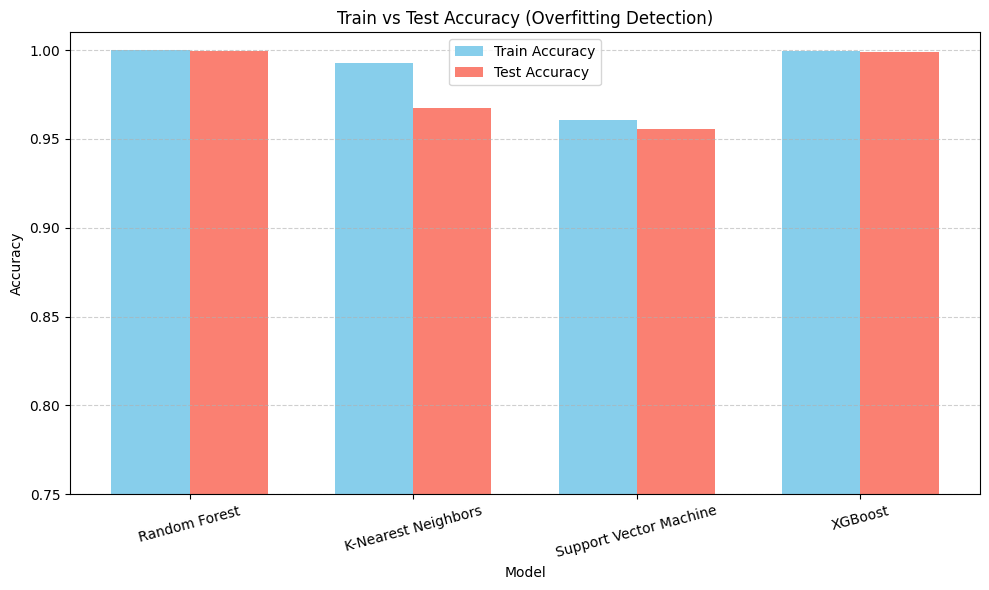

In [40]:
# Compute train/test accuracy for overfitting detection
train_accs = []
test_accs = []

for model_name, model in models.items():
    y_train_pred = model.predict(X_train_resampled)
    y_test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train_resampled, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

# Create overfitting DataFrame
overfit_df = pd.DataFrame({
    "Model": list(models.keys()),
    "Train Accuracy": train_accs,
    "Test Accuracy": test_accs
})
overfit_df["Gap"] = overfit_df["Train Accuracy"] - overfit_df["Test Accuracy"]

# Bar plot: Train vs Test Accuracy
plt.figure(figsize=(10, 6))
x = np.arange(len(overfit_df))
bar_width = 0.35

plt.bar(x - bar_width/2, overfit_df["Train Accuracy"], width=bar_width, label='Train Accuracy', color='skyblue')
plt.bar(x + bar_width/2, overfit_df["Test Accuracy"], width=bar_width, label='Test Accuracy', color='salmon')

plt.xticks(x, overfit_df["Model"], rotation=15)
plt.title("Train vs Test Accuracy (Overfitting Detection)")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.75, 1.01)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


 Learning Curve for the Best Generalizing Model

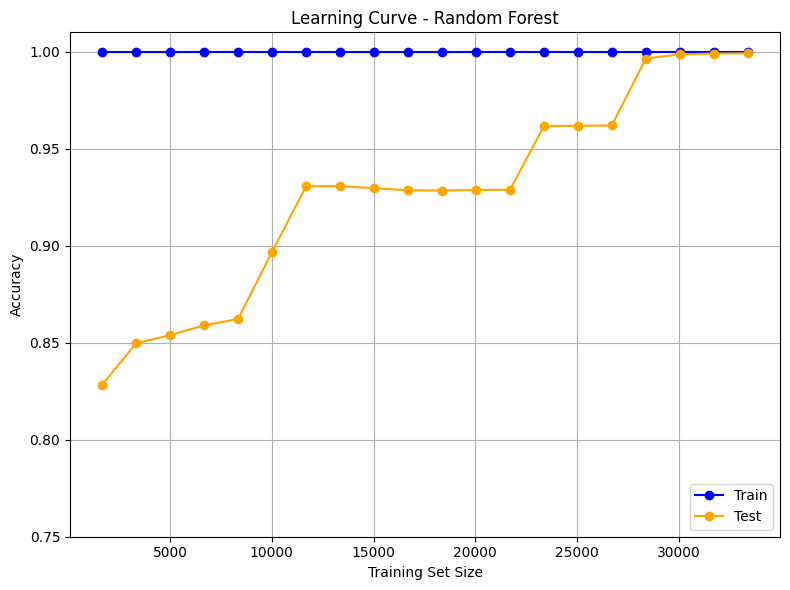

In [41]:

# Find best generalizing model (smallest train-test gap)
best_model_name = overfit_df.loc[overfit_df["Gap"].abs().idxmin(), "Model"]
best_model = models[best_model_name]

# Compute learning curve
train_sizes, train_scores, test_scores = learning_curve(
    best_model, X_train_resampled, y_train_resampled,
    cv=5, train_sizes=np.linspace(0.05, 1.0, 20), scoring='accuracy', n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot learning curve
plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', label="Train", color='blue')
plt.plot(train_sizes, test_mean, 'o-', label="Test", color='orange')
plt.title(f"Learning Curve - {best_model_name}")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.ylim(0.75, 1.01)
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Plot Confusion Matrix for Each Model on Test Set


 Fitting and evaluating Random Forest on the full training set...


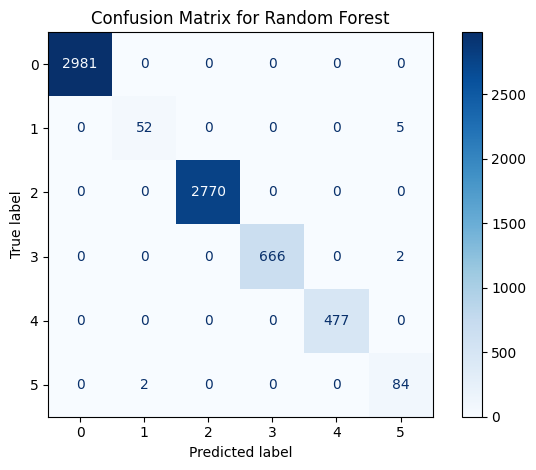


 Fitting and evaluating K-Nearest Neighbors on the full training set...


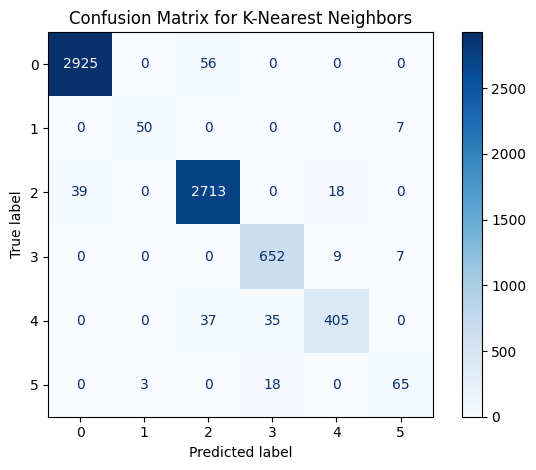


 Fitting and evaluating Support Vector Machine on the full training set...


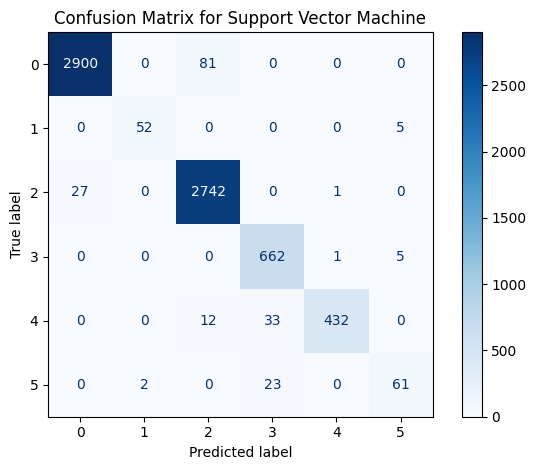


 Fitting and evaluating XGBoost on the full training set...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:21:16] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


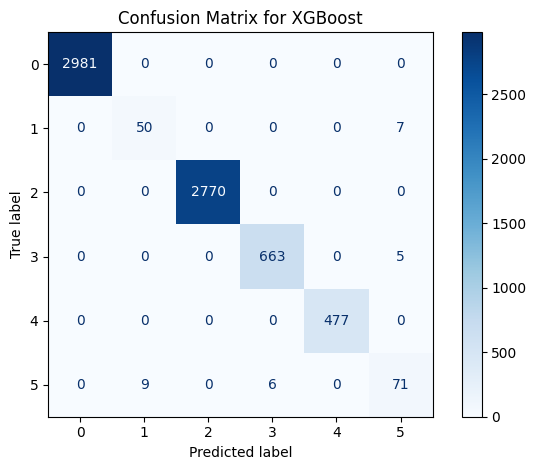

In [42]:
# Evaluate each model and plot confusion matrix
for name, model in models.items():
    print(f"\n Fitting and evaluating {name} on the full training set...")

    # Fit the model
    model.fit(X_train, y_train)

    # Predict labels
    y_pred = model.predict(X_test)

    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    disp.plot(cmap=plt.cm.Blues, values_format='d')  # Show integer counts
    plt.title(f"Confusion Matrix for {name}")
    plt.tight_layout()
    plt.show()
